# Credit Card Default Prediction & Risk Scoring

**Goal:** predict which credit card customers will default next month, and turn that prediction into
risk decisions a lender can act on.

**Workflow**
1. Data & behavioural features
2. Train / validation / test split, preprocessing, SMOTEENN (training data only)
3. Models: Logistic Regression, XGBoost, LightGBM, MLP, tuned LightGBM (Optuna), soft-voting ensemble
4. Model selection on the **validation** set, final numbers reported once on the **test** set
5. Risk layer: probability calibration, KS / Gini, risk bands A–E
6. Business layer: Expected Loss (PD × LGD × EAD) and a cost-based decision threshold
7. Explainability (SHAP), scoring the submission file, saving the model for the Streamlit app

> This is the cleaned-up version of `my-project2.ipynb` (kept for reference as the experiments notebook).

## 1. Setup

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))  # silences a joblib warning on Windows

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (fbeta_score, precision_score, recall_score, roc_auc_score,
                             roc_curve, brier_score_loss)
from imblearn.combine import SMOTEENN
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier, early_stopping
import optuna
import shap

from features import (add_features, feature_columns, CATEGORICAL_COLS, ENGINEERED_COLS,
                      ID_COL, TARGET)

RANDOM_STATE = 42
DATA_DIR = Path("data")
MODEL_DIR = Path("models");  MODEL_DIR.mkdir(exist_ok=True)
OUTPUT_DIR = Path("outputs"); OUTPUT_DIR.mkdir(exist_ok=True)

# Business assumptions (used in section 7)
LGD = 0.75            # Loss Given Default: share of the balance lost when a customer defaults
PROFIT_MARGIN = 0.15  # profit lost when a good customer is wrongly flagged (share of balance)

sns.set_style("whitegrid")

## 2. Data

In [2]:
train_df = pd.read_csv(DATA_DIR / "train_dataset_final1.csv")   # labelled
score_df = pd.read_csv(DATA_DIR / "validate_dataset_final.csv")  # unlabelled, to be scored

print("Labelled data :", train_df.shape)
print("Scoring data  :", score_df.shape)
print("Missing values:", train_df.isna().sum()[lambda s: s > 0].to_dict())
print(f"Default rate  : {train_df[TARGET].mean():.1%}")

Labelled data : (25247, 27)
Scoring data  : (5016, 26)
Missing values: {'age': 126}
Default rate  : 19.0%


- `age` has 126 missing values. Instead of dropping those rows (the old notebook did this, which also
  silently drops customers from the scoring file if they had missing values), they are filled with the
  **median age** inside the preprocessing step.
- Only ~19% of customers default → the classes are imbalanced, so accuracy is not a useful metric.

## 3. Behavioural features

Defined once in `features.py` and applied to every dataset (train, validation, test, scoring file, app input).

| Feature | Meaning |
|---|---|
| `delinquency_count` | number of months (out of 6) the customer paid late |
| `severe_delinquency_count` | months that were 3+ months late |
| `max_delay` | worst delay seen in the last 6 months |
| `max_delinquency_streak` | longest run of consecutive late months |
| `credit_utilization` | average bill ÷ credit limit |

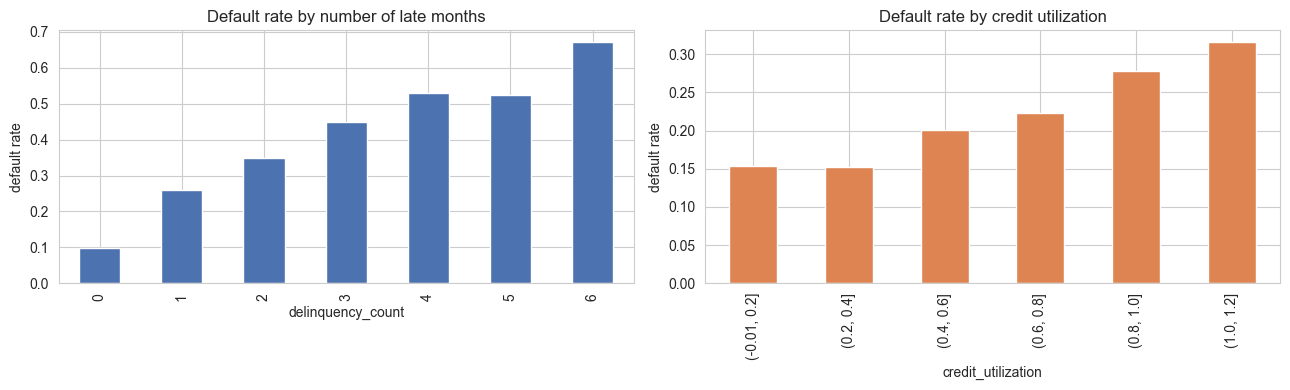

In [3]:
train_df = add_features(train_df)
score_df = add_features(score_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
train_df.groupby("delinquency_count")[TARGET].mean().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set(title="Default rate by number of late months", xlabel="delinquency_count", ylabel="default rate")
util_bins = pd.cut(train_df["credit_utilization"].clip(0, 1.2), bins=[-0.01, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2])
train_df.groupby(util_bins, observed=True)[TARGET].mean().plot.bar(ax=axes[1], color="#DD8452")
axes[1].set(title="Default rate by credit utilization", xlabel="credit_utilization", ylabel="default rate")
plt.tight_layout(); plt.show()

## 4. Train / validation / test split

Three separate sets, each with a single job:

| Set | Size | Used for |
|---|---|---|
| **Train** | 60% | fitting the models (after SMOTEENN) |
| **Validation** | 20% | early stopping, Optuna tuning, choosing thresholds, picking the best model, calibration |
| **Test** | 20% | touched **once**, at the end, to report final performance |

In the old notebook the threshold was tuned on the same data the score was reported on, which makes the
score look better than it really is. Keeping the test set separate gives an honest estimate.

In [4]:
FEATURES = feature_columns(train_df)
X, y = train_df[FEATURES], train_df[TARGET]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)

for name, part in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} {len(part):>6} rows | default rate {part.mean():.1%}")

train        15148 rows | default rate 19.0%
validation    5049 rows | default rate 19.0%
test          5050 rows | default rate 19.0%


## 5. Preprocessing and class imbalance

- **Numeric columns:** fill missing with the median, then standardise.
- **Categorical columns** (`sex`, `marriage`, `education`): one-hot encoded (in the old notebook these were
  accidentally fed to the models as plain numbers).
- The preprocessor is **fit on the training set only**, then applied to validation/test.
- **SMOTEENN** = SMOTE (creates synthetic defaulters) + Edited Nearest Neighbours (removes noisy,
  overlapping points). It is applied to the **training set only**: validation and test keep the real
  19% default rate, so the scores reflect reality.

In [5]:
numeric_cols = [c for c in FEATURES if c not in CATEGORICAL_COLS]

preprocessor = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
])

X_train_p = preprocessor.fit_transform(X_train)
X_val_p = preprocessor.transform(X_val)
X_test_p = preprocessor.transform(X_test)
feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]

X_train_bal, y_train_bal = SMOTEENN(random_state=RANDOM_STATE).fit_resample(X_train_p, y_train)

print("Before SMOTEENN:", y_train.value_counts().to_dict())
print("After  SMOTEENN:", pd.Series(y_train_bal).value_counts().to_dict())

  File "C:\Users\krish\AppData\Roaming\Python\Python312\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Program Files\Python312\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Before SMOTEENN: {0: 12264, 1: 2884}
After  SMOTEENN: {1: 10213, 0: 6782}


## 6. Models

**Why F2?** F2 weights recall twice as much as precision. Missing a real defaulter (lost money) is
more costly than wrongly flagging a good customer (a review or a lower limit), so recall matters more.

Each model outputs a probability. The cut-off (threshold) that maximises F2 is chosen on the
**validation** set and then applied unchanged to the test set.

In [6]:
THRESHOLDS = np.arange(0.01, 0.99, 0.01)

def best_f2_threshold(y_true, prob):
    """Threshold with the highest F2 score, and that score."""
    scores = [fbeta_score(y_true, prob >= t, beta=2) for t in THRESHOLDS]
    i = int(np.argmax(scores))
    return THRESHOLDS[i], scores[i]

val_probs, test_probs = {}, {}   # model name -> predicted probabilities

def record(name, model):
    val_probs[name] = model.predict_proba(X_val_p)[:, 1]
    test_probs[name] = model.predict_proba(X_test_p)[:, 1]
    t, f2 = best_f2_threshold(y_val, val_probs[name])
    print(f"{name:<20} validation F2 = {f2:.4f} at threshold {t:.2f}")

### 6.1 Baseline models

In [7]:
models = {}

models["Logistic Regression"] = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
models["Logistic Regression"].fit(X_train_bal, y_train_bal)
record("Logistic Regression", models["Logistic Regression"])

models["XGBoost"] = XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE)
models["XGBoost"].fit(X_train_bal, y_train_bal)
record("XGBoost", models["XGBoost"])

models["LightGBM"] = LGBMClassifier(learning_rate=0.05, n_estimators=1000,
                                    random_state=RANDOM_STATE, verbosity=-1)
models["LightGBM"].fit(X_train_bal, y_train_bal, eval_set=[(X_val_p, y_val)],
                       callbacks=[early_stopping(50, verbose=False)])
record("LightGBM", models["LightGBM"])

models["MLP (neural net)"] = MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                           max_iter=300, random_state=RANDOM_STATE)
models["MLP (neural net)"].fit(X_train_bal, y_train_bal)
record("MLP (neural net)", models["MLP (neural net)"])

Logistic Regression  validation F2 = 0.5885 at threshold 0.34


XGBoost              validation F2 = 0.5923 at threshold 0.13


LightGBM             validation F2 = 0.5971 at threshold 0.27


MLP (neural net)     validation F2 = 0.5674 at threshold 0.04


### 6.2 Tuned LightGBM (Optuna)

Optuna tries 30 hyper-parameter combinations, learning from earlier trials which regions look promising.
Each trial is scored by its best F2 on the validation set.

In [8]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 20, 100),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 3.0),
    }
    model = LGBMClassifier(**params, n_estimators=1000, random_state=RANDOM_STATE, verbosity=-1)
    model.fit(X_train_bal, y_train_bal, eval_set=[(X_val_p, y_val)],
              callbacks=[early_stopping(50, verbose=False)])
    trial.set_user_attr("n_estimators", model.best_iteration_)
    return best_f2_threshold(y_val, model.predict_proba(X_val_p)[:, 1])[1]

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=30)

best_params = {**study.best_params, "subsample_freq": 1,
               "n_estimators": study.best_trial.user_attrs["n_estimators"]}
print("Best parameters:", best_params)

models["Tuned LightGBM"] = LGBMClassifier(**best_params, random_state=RANDOM_STATE, verbosity=-1)
models["Tuned LightGBM"].fit(X_train_bal, y_train_bal)
record("Tuned LightGBM", models["Tuned LightGBM"])

Best parameters: {'learning_rate': 0.013107840286808248, 'num_leaves': 97, 'max_depth': 9, 'min_child_samples': 82, 'subsample': 0.7642319818616445, 'colsample_bytree': 0.6331782063032086, 'scale_pos_weight': 1.1920292773594467, 'subsample_freq': 1, 'n_estimators': 266}


Tuned LightGBM       validation F2 = 0.5969 at threshold 0.35


### 6.3 Soft-voting ensemble
Average the predicted probabilities of all the models above.

In [9]:
base = ["Logistic Regression", "XGBoost", "LightGBM", "MLP (neural net)", "Tuned LightGBM"]
val_probs["Ensemble (avg)"] = np.mean([val_probs[m] for m in base], axis=0)
test_probs["Ensemble (avg)"] = np.mean([test_probs[m] for m in base], axis=0)
t, f2 = best_f2_threshold(y_val, val_probs["Ensemble (avg)"])
print(f"{'Ensemble (avg)':<20} validation F2 = {f2:.4f} at threshold {t:.2f}")

Ensemble (avg)       validation F2 = 0.5961 at threshold 0.27


### 6.4 Comparison

The model is **chosen by validation F2**. The test columns show how each model does on unseen data with
the threshold fixed in advance.

In [10]:
rows = []
for name in val_probs:
    t, val_f2 = best_f2_threshold(y_val, val_probs[name])
    pred = test_probs[name] >= t
    rows.append({
        "model": name, "threshold": round(t, 2), "val_F2": val_f2,
        "val_ROC_AUC": roc_auc_score(y_val, val_probs[name]),
        "test_F2": fbeta_score(y_test, pred, beta=2),
        "test_recall": recall_score(y_test, pred),
        "test_precision": precision_score(y_test, pred),
        "test_ROC_AUC": roc_auc_score(y_test, test_probs[name]),
    })
results = pd.DataFrame(rows).sort_values("val_F2", ascending=False).reset_index(drop=True)
results.round(4)

,model,threshold,val_F2,val_ROC_AUC,test_F2,test_recall,test_precision,test_ROC_AUC
0,LightGBM,0.27,0.5971,0.7683,0.5945,0.7609,0.3172,0.7809
1,Tuned LightGBM,0.35,0.5969,0.7677,0.6091,0.8098,0.3059,0.7844
2,Ensemble (avg),0.27,0.5961,0.7677,0.5950,0.8119,0.2877,0.7775
3,XGBoost,0.13,0.5923,0.7604,0.5828,0.7807,0.2894,0.7650
4,Logistic Regression,0.34,0.5885,0.7504,0.5836,0.8867,0.2465,0.7669
5,MLP (neural net),0.04,0.5674,0.7280,0.5650,0.8202,0.2518,0.7321


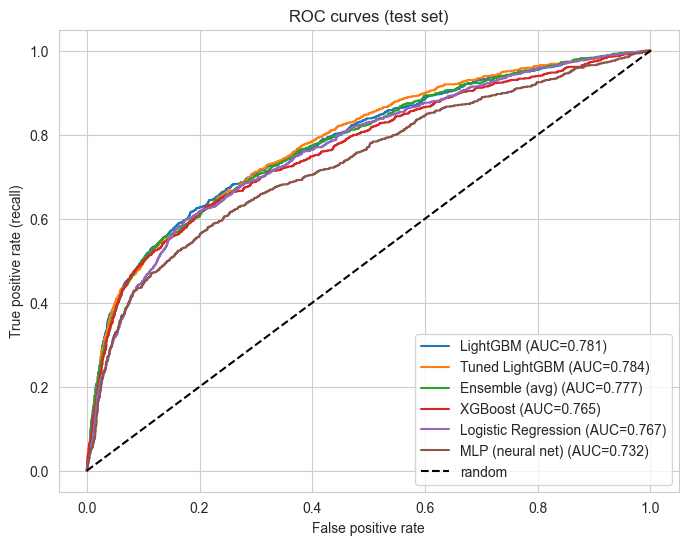

In [11]:
plt.figure(figsize=(8, 6))
for name in results["model"]:
    fpr, tpr, _ = roc_curve(y_test, test_probs[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, test_probs[name]):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="random")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate (recall)")
plt.title("ROC curves (test set)"); plt.legend(loc="lower right"); plt.show()

**What the comparison shows**

- **LightGBM has the best validation F2 (0.597)**, so it is the final model. Its test F2 is **0.595** with
  **76% recall** (3 out of 4 defaulters caught) and **ROC AUC 0.78**.
- **Tuned LightGBM and the ensemble are tied with it** (within 0.001 on validation). Optuna did not find
  anything better than LightGBM with early stopping, and averaging models did not help either, so the
  simpler single model is kept.
- Tuned LightGBM happens to score higher on the *test* set (0.609 vs 0.595), but choosing it for that
  reason would mean using the test set for model selection. The swap in ranking between validation and
  test shows that differences of ~0.01 F2 are just noise.
- Compared with the old notebook (LightGBM ROC AUC 0.765), AUC improved to 0.78 because the behavioural
  features now actually reach the model and the categorical columns are encoded properly.
- The old notebook's "peak F2 0.60" was measured on the same data used to tune the threshold, so it was
  optimistic. The 0.595 here comes from data the model never saw during any decision.

In [12]:
FINAL_MODEL_NAME = results.loc[0, "model"]   # best validation F2
print("Final model:", FINAL_MODEL_NAME)
final_model = models[FINAL_MODEL_NAME]
raw_val, raw_test = val_probs[FINAL_MODEL_NAME], test_probs[FINAL_MODEL_NAME]

Final model: LightGBM


## 7. From prediction to risk decisions

### 7.1 Calibration: turning scores into real probabilities

SMOTEENN trains the model on a ~50/50 dataset, so its raw scores are **inflated**: the average raw
score is far above the true 19% default rate. For pricing, provisioning or expected loss we need the
score to be an actual **probability of default (PD)**.

**Platt scaling:** fit a one-feature logistic regression on the validation set that maps the raw score
to the observed outcome. It is monotonic, so it does not change the ranking of customers (AUC stays
the same). It only fixes the scale.

In [13]:
def to_logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p)).reshape(-1, 1)

calibrator = LogisticRegression().fit(to_logit(raw_val), y_val)
pd_val = calibrator.predict_proba(to_logit(raw_val))[:, 1]
pd_test = calibrator.predict_proba(to_logit(raw_test))[:, 1]

print(f"Actual default rate (test) : {y_test.mean():.3f}")
print(f"Mean raw score             : {raw_test.mean():.3f}   Brier score {brier_score_loss(y_test, raw_test):.4f}")
print(f"Mean calibrated PD         : {pd_test.mean():.3f}   Brier score {brier_score_loss(y_test, pd_test):.4f}")
print(f"ROC AUC raw / calibrated   : {roc_auc_score(y_test, raw_test):.4f} / {roc_auc_score(y_test, pd_test):.4f}")

Actual default rate (test) : 0.190
Mean raw score             : 0.355   Brier score 0.1728
Mean calibrated PD         : 0.190   Brier score 0.1200
ROC AUC raw / calibrated   : 0.7809 / 0.7809


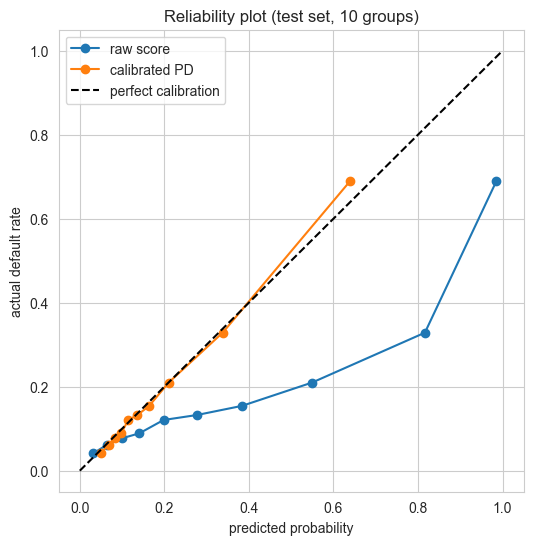

In [14]:
# Reliability plot: within each group of customers, does predicted PD match the actual default rate?
calib = pd.DataFrame({"raw": raw_test, "pd": pd_test, "y": y_test.values})
fig, ax = plt.subplots(figsize=(6, 6))
for col, label in [("raw", "raw score"), ("pd", "calibrated PD")]:
    g = calib.groupby(pd.qcut(calib[col], 10, duplicates="drop"), observed=True)
    ax.plot(g[col].mean(), g["y"].mean(), "o-", label=label)
ax.plot([0, 1], [0, 1], "k--", label="perfect calibration")
ax.set(xlabel="predicted probability", ylabel="actual default rate", title="Reliability plot (test set, 10 groups)")
ax.legend(); plt.show()

Because calibration is monotonic, the F2-optimal decision is unchanged. We simply re-express the
threshold on the PD scale so the rest of the project (bands, expected loss, app) works with real PDs.

In [15]:
F2_THRESHOLD, _ = best_f2_threshold(y_val, pd_val)
flag_f2 = pd_test >= F2_THRESHOLD
print(f"F2 threshold on PD scale: {F2_THRESHOLD:.2f}")
print(f"Test F2 {fbeta_score(y_test, flag_f2, beta=2):.4f} | recall {recall_score(y_test, flag_f2):.4f} | "
      f"precision {precision_score(y_test, flag_f2):.4f} | flagged {flag_f2.mean():.1%} of customers")

F2 threshold on PD scale: 0.13
Test F2 0.5955 | recall 0.7755 | precision 0.3088 | flagged 47.8% of customers


### 7.2 Credit-risk metrics: KS and Gini

Banks usually report these two alongside AUC:
- **Gini = 2 × AUC − 1.** 0 = random, 1 = perfect ranking.
- **KS (Kolmogorov–Smirnov)** = the largest gap between the share of defaulters and the share of
  non-defaulters captured as we move down the list of customers sorted by risk. A higher gap means
  better separation. In practice, a KS around 40+ is generally considered good for credit scorecards.

ROC AUC : 0.7809
Gini    : 0.5617
KS      : 43.2  (at PD = 0.199)


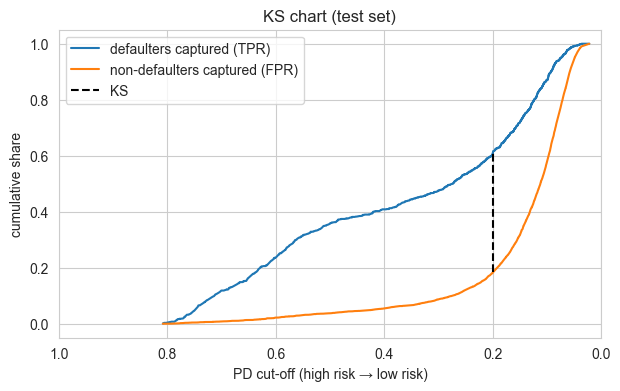

In [16]:
fpr, tpr, thr = roc_curve(y_test, pd_test)
ks_idx = np.argmax(tpr - fpr)
auc = roc_auc_score(y_test, pd_test)
print(f"ROC AUC : {auc:.4f}")
print(f"Gini    : {2 * auc - 1:.4f}")
print(f"KS      : {100 * (tpr - fpr)[ks_idx]:.1f}  (at PD = {thr[ks_idx]:.3f})")

plt.figure(figsize=(7, 4))
plt.plot(thr, tpr, label="defaulters captured (TPR)")
plt.plot(thr, fpr, label="non-defaulters captured (FPR)")
plt.vlines(thr[ks_idx], fpr[ks_idx], tpr[ks_idx], colors="k", linestyles="--", label="KS")
plt.gca().invert_xaxis(); plt.xlim(1, 0)
plt.xlabel("PD cut-off (high risk → low risk)"); plt.ylabel("cumulative share")
plt.title("KS chart (test set)"); plt.legend(); plt.show()

### 7.3 Risk bands A–E

Customers are split into five equal-sized bands by PD (cut-offs set on the validation set).
**A = lowest risk, E = highest risk.** A good model shows the actual default rate rising steadily from A to E.
This is how a lender would use the model in practice: e.g. auto-approve A–B, review C–D, decline or
reduce limits for E.

In [17]:
BAND_LABELS = ["A", "B", "C", "D", "E"]
BAND_EDGES = np.quantile(pd_val, [0.2, 0.4, 0.6, 0.8])   # 4 inner cut-offs -> 5 bands

def risk_band(pd_values):
    return np.array(BAND_LABELS)[np.digitize(pd_values, BAND_EDGES)]

test_view = X_test.copy()
test_view["actual_default"] = y_test.values
test_view["PD"] = pd_test
test_view["band"] = risk_band(pd_test)

band_table = test_view.groupby("band").agg(
    customers=("PD", "size"),
    avg_PD=("PD", "mean"),
    actual_default_rate=("actual_default", "mean"),
    defaulters=("actual_default", "sum"),
)
band_table["share_of_all_defaulters"] = band_table["defaulters"] / band_table["defaulters"].sum()
print("PD cut-offs between bands:", np.round(BAND_EDGES, 3))
band_table.round(3)

PD cut-offs between bands: [0.076 0.106 0.149 0.249]


,customers,avg_PD,actual_default_rate,defaulters,share_of_all_defaulters
band,,,,,
A,1006,0.059,0.052,52,0.054
B,1027,0.091,0.083,85,0.088
C,1006,0.126,0.127,128,0.133
D,999,0.187,0.183,183,0.190
E,1012,0.488,0.508,514,0.534


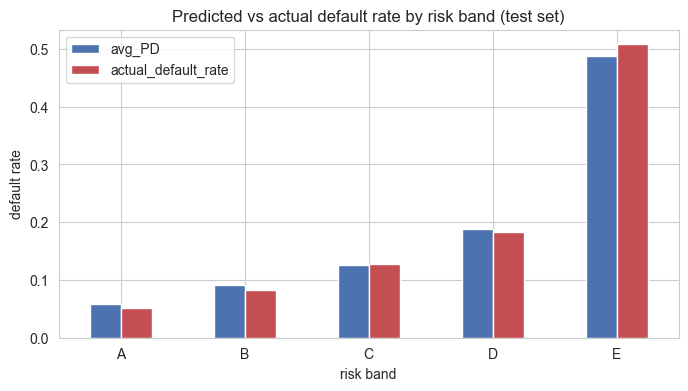

In [18]:
ax = band_table[["avg_PD", "actual_default_rate"]].plot.bar(figsize=(8, 4), rot=0, color=["#4C72B0", "#C44E52"])
ax.set(title="Predicted vs actual default rate by risk band (test set)", ylabel="default rate", xlabel="risk band")
plt.show()

### 7.4 Expected Loss (EL = PD × LGD × EAD)

The standard credit-risk formula for how much money we expect to lose on each customer:
- **PD** — probability of default (from the calibrated model)
- **LGD** — Loss Given Default: share of the balance not recovered. Assumed **75%**, a typical level for
  unsecured credit card debt.
- **EAD** — Exposure at Default: what the customer owes. Approximated by the latest bill (`Bill_amt1`,
  negative balances set to 0).

If the PDs are well calibrated, the total expected loss should be close to the loss that actually happened.

In [19]:
test_view["EAD"] = test_view["Bill_amt1"].clip(lower=0)
test_view["expected_loss"] = test_view["PD"] * LGD * test_view["EAD"]
test_view["actual_loss"] = test_view["actual_default"] * LGD * test_view["EAD"]

print(f"Total exposure (EAD)          : {test_view['EAD'].sum():>15,.0f}")
print(f"Expected loss (model)         : {test_view['expected_loss'].sum():>15,.0f}")
print(f"Actual loss (realised)        : {test_view['actual_loss'].sum():>15,.0f}")

el_by_band = test_view.groupby("band")[["EAD", "expected_loss", "actual_loss"]].sum()
el_by_band["share_of_expected_loss"] = el_by_band["expected_loss"] / el_by_band["expected_loss"].sum()
el_by_band.round(2)

Total exposure (EAD)          :     258,449,088
Expected loss (model)         :      34,180,248
Actual loss (realised)        :      33,566,668


,EAD,expected_loss,actual_loss,share_of_expected_loss
band,,,,
A,76408591.72,3365434.41,2673509.22,0.10
B,63879093.78,4288363.89,4607880.94,0.13
C,44837643.24,4147370.79,3817148.56,0.12
D,27586698.21,3819656.29,2864653.40,0.11
E,45737061.33,18559422.73,19603476.26,0.54


### 7.5 Cost-based threshold

F2 says "recall is 2× as important as precision", but we can pick the cut-off from money instead:

- **Missed defaulter (false negative):** we lose `LGD × EAD` (75% of the balance)
- **Wrongly flagged good customer (false positive):** we lose the profit on that customer, assumed
  `PROFIT_MARGIN × EAD` (15% of the balance)

Flag a customer when the expected cost of *not* flagging is higher than the cost of flagging:

`PD × LGD > (1 − PD) × PROFIT_MARGIN`  ⟹  flag if `PD > PROFIT_MARGIN / (PROFIT_MARGIN + LGD)`

With well-calibrated PDs this gives the threshold directly. We also check it empirically on the
validation set.

Theoretical threshold : 0.167
Empirical (validation): 0.13


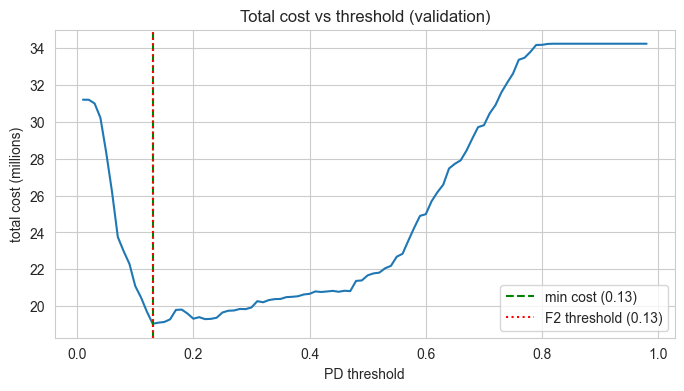

In [20]:
def total_cost(y_true, pd_values, ead, threshold):
    flag = pd_values >= threshold
    missed_defaulters = (~flag) & (y_true == 1)
    false_alarms = flag & (y_true == 0)
    return (missed_defaulters * LGD * ead).sum() + (false_alarms * PROFIT_MARGIN * ead).sum()

ead_val = X_val["Bill_amt1"].clip(lower=0).values
ead_test = test_view["EAD"].values

theory_threshold = PROFIT_MARGIN / (PROFIT_MARGIN + LGD)
val_costs = [total_cost(y_val.values, pd_val, ead_val, t) for t in THRESHOLDS]
COST_THRESHOLD = THRESHOLDS[int(np.argmin(val_costs))]
print(f"Theoretical threshold : {theory_threshold:.3f}")
print(f"Empirical (validation): {COST_THRESHOLD:.2f}")

plt.figure(figsize=(8, 4))
plt.plot(THRESHOLDS, np.array(val_costs) / 1e6)
plt.axvline(COST_THRESHOLD, color="g", ls="--", label=f"min cost ({COST_THRESHOLD:.2f})")
plt.axvline(F2_THRESHOLD, color="r", ls=":", label=f"F2 threshold ({F2_THRESHOLD:.2f})")
plt.xlabel("PD threshold"); plt.ylabel("total cost (millions)"); plt.title("Total cost vs threshold (validation)")
plt.legend(); plt.show()

In [21]:
policies = {
    "Flag nobody": 1.01,
    f"F2 threshold ({F2_THRESHOLD:.2f})": F2_THRESHOLD,
    f"Cost threshold, validation ({COST_THRESHOLD:.2f})": COST_THRESHOLD,
    f"Cost threshold, formula ({theory_threshold:.2f})": theory_threshold,
}
rows = []
for name, t in policies.items():
    flag = pd_test >= t
    rows.append({
        "policy": name,
        "flagged_customers": f"{flag.mean():.1%}",
        "recall": recall_score(y_test, flag, zero_division=0),
        "precision": precision_score(y_test, flag, zero_division=0),
        "total_cost": total_cost(y_test.values, pd_test, ead_test, t),
    })
policy_table = pd.DataFrame(rows)
policy_table["saving_vs_flag_nobody"] = 1 - policy_table["total_cost"] / policy_table.loc[0, "total_cost"]
policy_table.round(3)

,policy,flagged_customers,recall,precision,total_cost,saving_vs_flag_nobody
0,Flag nobody,0.0%,0.000,0.000,3.356667e+07,0.000
1,F2 threshold (0.13),47.8%,0.775,0.309,1.848508e+07,0.449
2,"Cost threshold, validation (0.13)",47.8%,0.775,0.309,1.848508e+07,0.449
3,"Cost threshold, formula (0.17)",34.0%,0.682,0.382,1.693662e+07,0.495


**What this shows**

- On validation the cheapest threshold is **0.13**, the same as the F2 threshold. Under these assumptions
  (losing 75% of a defaulter's balance vs 15% profit on a good customer), "recall is 2× as important as
  precision" lands in the low-cost region.
- The cost curve is **flat and noisy** around its minimum: on validation every threshold between 0.13 and
  0.21 costs within ~4% of the best. That is why the test set prefers a slightly different point.
- On the test set the **formula threshold (0.17)** is the cheapest: about **50% lower loss than flagging
  nobody**, vs 45% for the F2 threshold, while flagging **34% of customers instead of 48%** (less review work).
  The formula does not depend on any particular sample, so it is the more robust choice.
- **Why this matters:** F2 is fixed, but the cost threshold moves with the business. If profit per good
  customer goes up, the formula raises the threshold and fewer customers get flagged.
- **Simplifying assumption:** a flagged customer's loss is fully avoided (e.g. the limit is cut before they
  default). In reality only part of it would be avoided.

## 8. Explainability (SHAP)

SHAP shows how much each feature pushes a customer's risk up (red dots on the right) or down.
The Streamlit app uses the same values to show the top reasons behind each individual prediction.

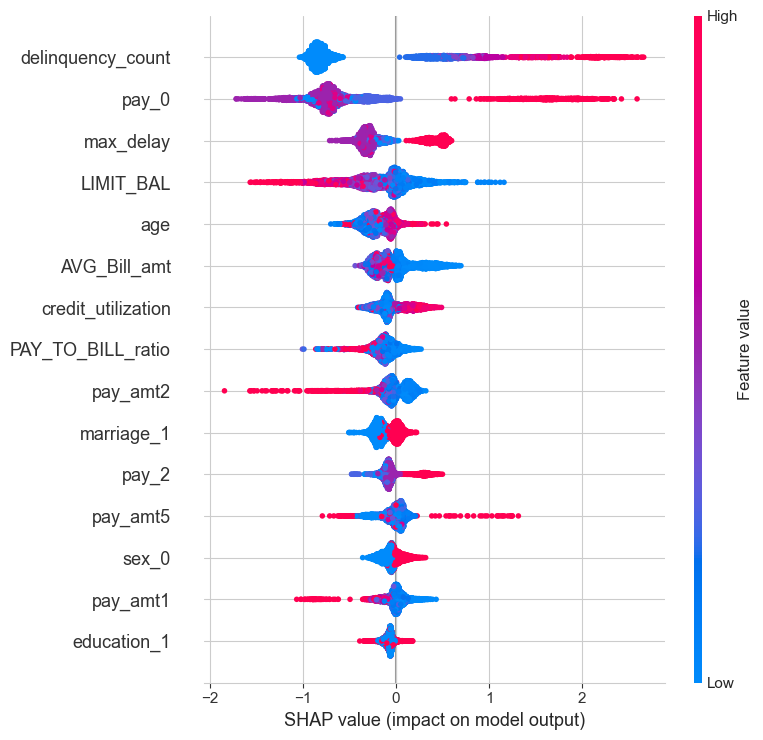

In [22]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test_p)
shap.summary_plot(shap_values, X_test_p, feature_names=feature_names, max_display=15)

## 9. Score the submission file and save the model

`outputs/predictions.csv` contains, for every customer in `validate_dataset_final.csv`:
the F2-based decision (`next_month_default`), the calibrated PD, the risk band and the expected loss.

`models/credit_risk_model.joblib` bundles everything the Streamlit app needs.

In [23]:
score_p = preprocessor.transform(score_df[FEATURES])
score_pd = calibrator.predict_proba(to_logit(final_model.predict_proba(score_p)[:, 1]))[:, 1]

predictions = pd.DataFrame({
    ID_COL: score_df[ID_COL],
    "next_month_default": (score_pd >= F2_THRESHOLD).astype(int),
    "probability_of_default": score_pd.round(4),
    "risk_band": risk_band(score_pd),
    "expected_loss": (score_pd * LGD * score_df["Bill_amt1"].clip(lower=0)).round(2),
})
predictions.to_csv(OUTPUT_DIR / "predictions.csv", index=False)
print(f"Scored {len(predictions)} customers (none dropped).")
print(predictions["risk_band"].value_counts().sort_index().to_dict())
predictions.head()

Scored 5016 customers (none dropped).
{'A': 985, 'B': 971, 'C': 1018, 'D': 1021, 'E': 1021}


,Customer_ID,next_month_default,probability_of_default,risk_band,expected_loss
0,1,0,0.0944,B,2042.18
1,2,0,0.0644,A,214.46
2,3,1,0.1361,C,30681.89
3,4,1,0.4052,E,3229.74
4,5,0,0.0329,A,2429.95


In [24]:
joblib.dump({
    "model_name": FINAL_MODEL_NAME,
    "preprocessor": preprocessor,
    "model": final_model,
    "calibrator": calibrator,
    "features": FEATURES,
    "feature_names": feature_names,
    "f2_threshold": float(F2_THRESHOLD),
    "cost_threshold": float(COST_THRESHOLD),
    "band_edges": BAND_EDGES.tolist(),
    "band_labels": BAND_LABELS,
    "band_default_rates": band_table["actual_default_rate"].round(4).to_dict(),
    "lgd": LGD,
    "profit_margin": PROFIT_MARGIN,
}, MODEL_DIR / "credit_risk_model.joblib")
print("Saved", MODEL_DIR / "credit_risk_model.joblib")

Saved models\credit_risk_model.joblib


## 10. Summary

| | Result (test set, never used for any decision) |
|---|---|
| Final model | LightGBM (best validation F2) |
| F2 / recall / precision | 0.595 / 0.76 / 0.32 |
| ROC AUC / Gini / KS | 0.78 / 0.56 / 43 |
| Calibration | mean PD 19.0% vs actual 19.0%; Brier 0.173 → 0.120 |
| Risk bands | default rate rises from 5% (band A) to 51% (band E); band E holds 53% of all defaulters |
| Expected loss | predicted 34.2M vs actual 33.6M (within 2%) |
| Decision policy | F2 threshold (0.13): 45% lower loss than flagging nobody, 48% flagged. Cost formula (0.17): 50% lower loss, 34% flagged |

**Fixes compared with the old notebook**
1. Separate train / validation / test sets: thresholds, tuning and model choice use validation only.
2. Behavioural features are now actually used by the model (previously only plotted).
3. Categorical columns are one-hot encoded instead of being treated as numbers.
4. Missing `age` is imputed instead of dropping rows, so every customer in the scoring file gets a prediction.
5. Stacking that was trained and evaluated on the test labels was removed (the simple average shows ensembling does not help here).

**Limitations**
- LGD (75%) and profit margin (15%) are assumptions, not estimated from data.
- EAD uses the latest bill only; a bank would also add part of the unused credit limit.
- One train/validation/test split: scores move by about ±0.01 depending on the split.
- `sex`, `marriage` and `age` are model inputs; a real lender would need a fair-lending review before using them.